In [22]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from google.colab import files

model = tf.keras.applications.MobileNetV2(weights="imagenet")

print("VisionPort photo-recognition model loaded!")

14536120/14536120 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
VisionPort photo-recognition model loaded!


Saving Ginger Cat Amid Greenery.png to Ginger Cat Amid Greenery.png
35363/35363 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


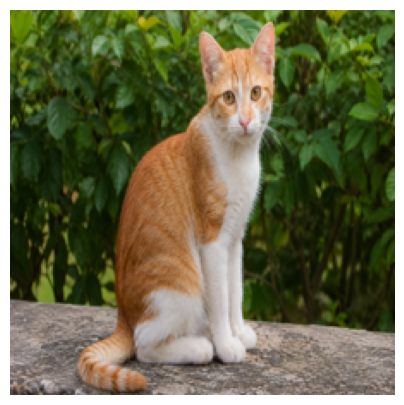

VisionPort prediction results:
tiger cat: 45.78%
Egyptian cat: 26.17%
tabby: 5.27%


In [23]:
uploaded = files.upload()

if uploaded:
    filename = next(iter(uploaded))

    # Load the user's photo
    image = Image.open(filename).convert("RGB")
    image = image.resize((224, 224))

    # Prepare image for MobileNetV2
    image_array = np.array(image, dtype=np.float32)
    image_array = tf.keras.applications.mobilenet_v2.preprocess_input(
        image_array
    )
    image_array = np.expand_dims(image_array, axis=0)

    # Predict the image category
    predictions = model.predict(image_array, verbose=0)

    results = tf.keras.applications.mobilenet_v2.decode_predictions(
        predictions, top=3
    )[0]

    # Display photo
    plt.figure(figsize=(5, 5))
    plt.imshow(image)
    plt.axis("off")
    plt.show()

    print("VisionPort prediction results:")
    for _, label, score in results:
        print(f"{label.replace('_', ' ')}: {score:.2%}")